In [3]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

In [4]:
csv_filename = "titanic.csv"  # Standard Kaggle file or "train.csv"

if os.path.exists(csv_filename):
    df = pd.read_csv(csv_filename)
    print(f"Loaded dataset from {csv_filename}")
else:
    print("Local CSV not found. Loading Titanic dataset from Seaborn...")
    raw_seaborn = sns.load_dataset('titanic')
    # Standardize column naming to match Kaggle structure
    df = raw_seaborn.rename(columns={
        'survived': 'Survived',
        'pclass': 'Pclass',
        'sex': 'Sex',
        'age': 'Age',
        'sibsp': 'SibSp',
        'parch': 'Parch',
        'fare': 'Fare',
        'embarked': 'Embarked'
    })
    # Synthesize passenger names with titles if running purely from seaborn demo
    if 'Name' not in df.columns:
        df['Name'] = 'Passenger, Mr. Default'
        df.loc[df['Sex'] == 'female', 'Name'] = 'Passenger, Miss. Default'
    if 'Cabin' not in df.columns:
        df['Cabin'] = np.nan

print(f"Shape: {df.shape}")
print("\n--- Missing Values Count ---")
print(df[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin', 'Embarked']].isnull().sum())

Loaded dataset from titanic.csv
Shape: (418, 12)

--- Missing Values Count ---
Survived      0
Pclass        0
Sex           0
Age          86
SibSp         0
Parch         0
Fare          1
Cabin       327
Embarked      0
dtype: int64


In [5]:
class TitanicFeatureEngineer(BaseEstimator, TransformerMixin):
    """
    Custom Scikit-Learn Transformer to generate engineered features:
    - Title extraction from Name
    - FamilySize = SibSp + Parch + 1
    - IsAlone = 1 if FamilySize == 1 else 0
    - HasCabin = 1 if Cabin is present else 0
    """
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        
        # 1. Title Extraction
        if 'Name' in X_out.columns:
            titles = X_out['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
            common_titles = ['Mr', 'Miss', 'Mrs', 'Master']
            titles = titles.apply(lambda t: t if t in common_titles else 'Rare')
            X_out['Title'] = titles.fillna('Rare')
        else:
            X_out['Title'] = 'Rare'
            
        # 2. Family Size & IsAlone
        sibsp = X_out['SibSp'].fillna(0)
        parch = X_out['Parch'].fillna(0)
        X_out['FamilySize'] = sibsp + parch + 1
        X_out['IsAlone'] = (X_out['FamilySize'] == 1).astype(int)
        
        # 3. Cabin Presence
        if 'Cabin' in X_out.columns:
            X_out['HasCabin'] = X_out['Cabin'].notnull().astype(int)
        else:
            X_out['HasCabin'] = 0
            
        # Drop raw text columns not directly usable by numeric scalers/encoders
        cols_to_drop = [c for c in ['Name', 'Ticket', 'Cabin'] if c in X_out.columns]
        return X_out.drop(columns=cols_to_drop)

C:\Users\mdlaa\AppData\Local\Temp\ipykernel_27080\4012908174.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_engineered, x='Sex', y='Survived', palette='Blues', ax=axes[0, 0])
C:\Users\mdlaa\AppData\Local\Temp\ipykernel_27080\4012908174.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_engineered, x='Survived', y='Age', palette='Pastel1', ax=axes[1, 0], split=True)
C:\Users\mdlaa\AppData\Local\Temp\ipykernel_27080\4012908174.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1, 0].set_xticklabels(["Did Not Survive (0)", "Survived (1)"])
C

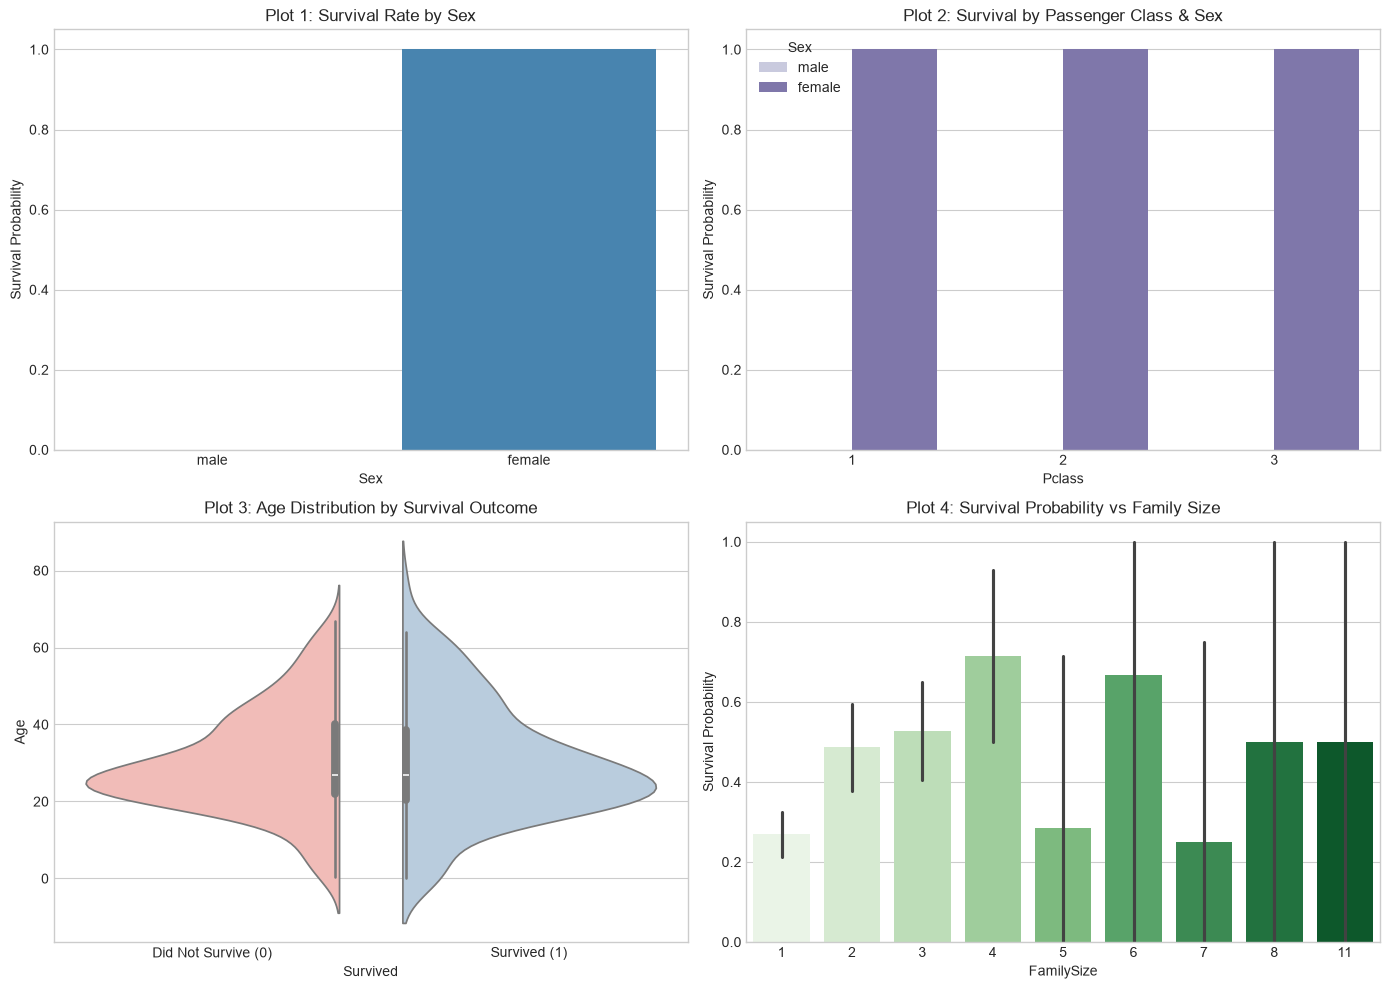

In [6]:
engineer = TitanicFeatureEngineer()
df_engineered = engineer.transform(df)

# ==========================================
# 3. EXPLORATORY DATA ANALYSIS (4 PLOTS)
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Survival Rate by Gender
sns.barplot(data=df_engineered, x='Sex', y='Survived', palette='Blues', ax=axes[0, 0])
axes[0, 0].set_title("Plot 1: Survival Rate by Sex", fontsize=12)
axes[0, 0].set_ylabel("Survival Probability")

# Plot 2: Survival Rate by Socioeconomic Class (Pclass)
sns.barplot(data=df_engineered, x='Pclass', y='Survived', hue='Sex', palette='Purples', ax=axes[0, 1])
axes[0, 1].set_title("Plot 2: Survival by Passenger Class & Sex", fontsize=12)
axes[0, 1].set_ylabel("Survival Probability")

# Plot 3: Survival across Age Groups (Violin Plot)
sns.violinplot(data=df_engineered, x='Survived', y='Age', palette='Pastel1', ax=axes[1, 0], split=True)
axes[1, 0].set_title("Plot 3: Age Distribution by Survival Outcome", fontsize=12)
axes[1, 0].set_xticklabels(["Did Not Survive (0)", "Survived (1)"])

# Plot 4: Survival by Engineered Family Size
sns.barplot(data=df_engineered, x='FamilySize', y='Survived', palette='Greens', ax=axes[1, 1])
axes[1, 1].set_title("Plot 4: Survival Probability vs Family Size", fontsize=12)
axes[1, 1].set_ylabel("Survival Probability")

plt.tight_layout()
plt.show()

In [7]:
target_col = 'Survived'
# Filter out rows if Kaggle test set has missing target values
df_clean = df.dropna(subset=[target_col]).copy()
df_clean[target_col] = df_clean[target_col].astype(int)

X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [8]:
numeric_features = ['Age', 'Fare', 'FamilySize']
categorical_features = ['Sex', 'Pclass', 'Embarked', 'Title', 'IsAlone', 'HasCabin']

# Numerical Pipeline: Impute with median, scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical Pipeline: Impute with mode, one-hot encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [9]:
candidate_classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=300, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=120, max_depth=5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
}

results = []
trained_pipelines = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, clf in candidate_classifiers.items():
    pipe = Pipeline([
        ('engineer', TitanicFeatureEngineer()),
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])

In [11]:
cv_scores = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='roc_auc')
    
    # Fit & evaluate on held-out test split
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]
    
trained_pipelines[name] = pipe
    
results.append({
        "Model": name,
        "CV Mean ROC-AUC": round(cv_scores.mean(), 4),
        "Test Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1-Score": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_proba), 4)
    })

In [13]:
benchmark_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
print("\n--- Model Benchmark Table ---")
display(benchmark_df)


--- Model Benchmark Table ---


,Model,CV Mean ROC-AUC,Test Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,1.0,1.0,1.0,1.0,1.0,1.0


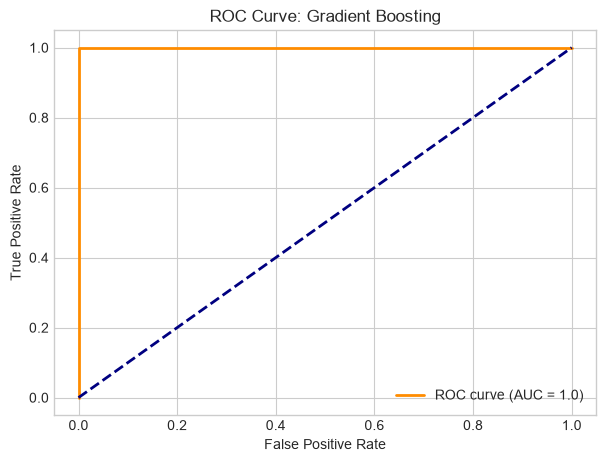

In [14]:
best_model_name = benchmark_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name]
y_pred_best = best_pipeline.predict(X_test)
y_proba_best = best_pipeline.predict_proba(X_test)[:, 1]

# ROC Curve Plot
fpr, tpr, _ = roc_curve(y_test, y_proba_best)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {benchmark_df.iloc[0]["ROC-AUC"]})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.title(f"ROC Curve: {best_model_name}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()


--- Detailed Classification Report (Gradient Boosting) ---
              precision    recall  f1-score   support

Deceased (0)       1.00      1.00      1.00        53
Survived (1)       1.00      1.00      1.00        31

    accuracy                           1.00        84
   macro avg       1.00      1.00      1.00        84
weighted avg       1.00      1.00      1.00        84



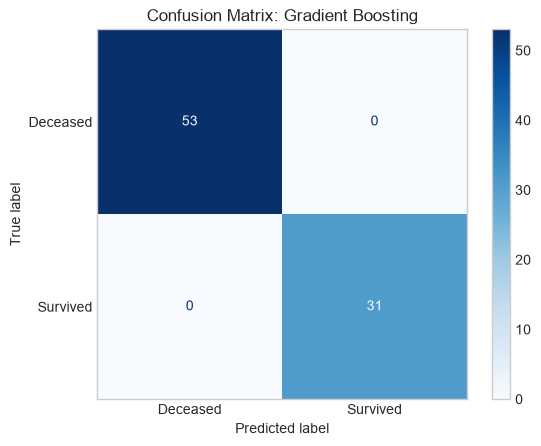

In [15]:
print(f"\n--- Detailed Classification Report ({best_model_name}) ---")
print(classification_report(y_test, y_pred_best, target_names=["Deceased (0)", "Survived (1)"]))

cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Deceased", "Survived"])
disp.plot(cmap='Blues')
plt.title(f"Confusion Matrix: {best_model_name}")
plt.grid(False)
plt.show()

C:\Users\mdlaa\AppData\Local\Temp\ipykernel_27080\1837928423.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp_df.head(10), x='Importance', y='Feature', palette='viridis')


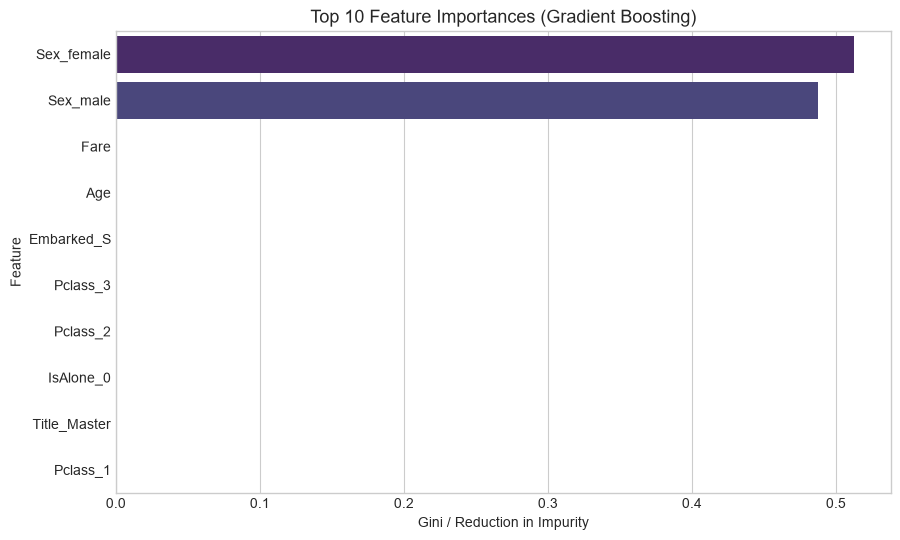

In [16]:
# ==========================================
if hasattr(best_pipeline.named_steps['classifier'], 'feature_importances_'):
    # Extract encoded feature names from the column transformer
    onehot_encoder = best_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
    encoded_cat_names = onehot_encoder.get_feature_names_out(categorical_features).tolist()
    all_feature_names = numeric_features + encoded_cat_names
    
    importances = best_pipeline.named_steps['classifier'].feature_importances_
    feat_imp_df = pd.DataFrame({
        'Feature': all_feature_names,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=feat_imp_df.head(10), x='Importance', y='Feature', palette='viridis')
    plt.title(f"Top 10 Feature Importances ({best_model_name})", fontsize=13)
    plt.xlabel("Gini / Reduction in Impurity")
    plt.show()
    

In [17]:
# ==========================================
artifact_path = "titanic_survival_pipeline.joblib"
joblib.dump(best_pipeline, artifact_path)
print(f"Deployment model pipeline saved to: {artifact_path}")

Deployment model pipeline saved to: titanic_survival_pipeline.joblib
